# Testing and performance

Based on the performance on validation set, we choose kNN for score prediction and XGBoost for cost prediction and the routing policy defined before. We now run this policy on the test data set. 

In [1]:
# Load the saved policy and test prompts

from pathlib import Path
import json
import sys
import importlib

import joblib
import numpy as np
import pandas as pd
from scipy.sparse import load_npz

PROJECT_DIR = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "1_data_preparation").is_dir()
    ),
    None,
)

if PROJECT_DIR is None:
    raise FileNotFoundError("Run this notebook from inside the project.")

DATA_DIR = (
    PROJECT_DIR
    / "1_data_preparation/data/processed/char_tfidf_50k"
)

POLICY_PATH = (
    PROJECT_DIR / "artifacts" / "router_knn_xgb" / "policy.json"
)

with POLICY_PATH.open() as file:
    policy_config = json.load(file)

selected_lambda = float(policy_config["lambda"])
REFERENCE_MODEL = policy_config["reference_model"]
model_names = policy_config["model_order"]
validation_target = policy_config["validation_quality_target"]

assert policy_config["cost_units"] == "dollars_per_prompt"

test_questions = pd.read_pickle(DATA_DIR / "test_questions.pkl")

print("Test prompts:", len(test_questions))
print("Fixed lambda:", selected_lambda)
print("Saved validation quality target:", validation_target)

Test prompts: 7300
Fixed lambda: 2.7142066911362983
Saved validation quality target: 0.78785968758564


## Testing

In [2]:
# Predict scores using kNN
module_dir = str(PROJECT_DIR / "2a_Score_training_calibration")

if module_dir not in sys.path:
    sys.path.insert(0, module_dir)

import score_model_knn as knn_module

importlib.reload(knn_module)

SCORE_MODEL_DIR = PROJECT_DIR / policy_config["score_artifact"]

with (SCORE_MODEL_DIR / "metadata.json").open() as file:
    score_metadata = json.load(file)

score_knn = joblib.load(
    SCORE_MODEL_DIR / score_metadata["model_file"]
)

score_vectorizer = joblib.load(
    SCORE_MODEL_DIR / score_metadata["vectorizer_file"]
)

X_test_score = score_vectorizer.transform(
    test_questions["question_text"]
)

assert X_test_score.shape[1] == score_metadata["n_features"]
assert set(score_metadata["model_names"]) == set(model_names)

selected_k = score_metadata["k"]

score_predictions = knn_module.predict_score_grid(
    score_knn,
    X_test_score,
    k_values=[selected_k],
    batch_size=score_metadata["batch_size"],
)[selected_k]

q_hat_test = pd.DataFrame(
    score_predictions,
    index=test_questions.index,
    columns=score_metadata["model_names"],
).loc[:, model_names]

print("Score predictions:", q_hat_test.shape)

Score predictions: (7300, 11)


In [3]:
# Import reusable cost-model loading and dollar prediction helpers.
module_dir = str(PROJECT_DIR / "2b_cost_training_calibration")

if module_dir not in sys.path:
    sys.path.insert(0, module_dir)

import cost_model_xgb as cost_module

importlib.reload(cost_module)

# Predict test costs using the artifact referenced by the saved policy.
COST_MODEL_DIR = PROJECT_DIR / policy_config["cost_artifact"]

cost_models, cost_metadata = cost_module.load_cost_models(COST_MODEL_DIR)

X_test_cost = load_npz(DATA_DIR / "X_test.npz")

assert X_test_cost.shape[0] == len(test_questions)
assert set(cost_models) == set(model_names)

c_hat_test = cost_module.predict_costs(
    X_test_cost,
    cost_models,
    cost_metadata,
    index=test_questions.index,
).loc[:, model_names]

assert q_hat_test.index.equals(c_hat_test.index)
assert q_hat_test.columns.equals(c_hat_test.columns)
assert np.isfinite(q_hat_test.to_numpy()).all()
assert np.isfinite(c_hat_test.to_numpy()).all()
assert q_hat_test.ge(0).all().all()
assert q_hat_test.le(1).all().all()
assert c_hat_test.ge(0).all().all()

print("Cost predictions:", c_hat_test.shape)

Cost predictions: (7300, 11)


In [4]:
# Apply the fixed routing policy
utility = (
    q_hat_test.to_numpy()
    - selected_lambda * c_hat_test.to_numpy()
)

chosen_columns = utility.argmax(axis=1)
rows = np.arange(len(test_questions))

test_routing_details = test_questions[
    ["sample_id", "eval_name", "question_group"]
].copy()

test_routing_details["chosen_model"] = (
    q_hat_test.columns.to_numpy()[chosen_columns]
)

test_routing_details["predicted_score"] = (
    q_hat_test.to_numpy()[rows, chosen_columns]
)

test_routing_details["predicted_cost"] = (
    c_hat_test.to_numpy()[rows, chosen_columns]
)

print("Routing decisions made:", len(test_routing_details))

Routing decisions made: 7300


In [5]:
# Load outcomes and test performance

test_scores = pd.read_pickle(
    DATA_DIR / "test_scores.pkl"
).astype(float)

test_costs = pd.read_pickle(
    DATA_DIR / "test_costs.pkl"
).astype(float)

assert test_scores.index.equals(test_questions.index)
assert test_costs.index.equals(test_questions.index)

test_scores = test_scores.loc[:, model_names]
test_costs = test_costs.loc[:, model_names]

assert np.isfinite(test_scores.to_numpy()).all()
assert np.isfinite(test_costs.to_numpy()).all()

test_routing_details["observed_score"] = (
    test_scores.to_numpy()[rows, chosen_columns]
)

test_routing_details["observed_cost"] = (
    test_costs.to_numpy()[rows, chosen_columns]
)

test_routing_details["gpt4_score"] = test_scores[REFERENCE_MODEL]
test_routing_details["gpt4_cost"] = test_costs[REFERENCE_MODEL]

reference_score = test_scores[REFERENCE_MODEL].mean()
reference_cost = test_costs[REFERENCE_MODEL].mean()

assert reference_cost > 0

test_comparison = pd.DataFrame({
    "observed_mean_score": [
        reference_score,
        test_routing_details["observed_score"].mean(),
    ],
    "cost_per_1000_prompts": [
        1000 * reference_cost,
        1000 * test_routing_details["observed_cost"].mean(),
    ],
}, index=[
    "Always GPT-4",
    "kNN + XGBoost router",
])

test_comparison["quality_gap_vs_test_gpt4"] = (
    test_comparison["observed_mean_score"] - reference_score
)

test_comparison["gap_vs_saved_validation_target"] = (
    test_comparison["observed_mean_score"] - validation_target
)

test_comparison["savings_per_1000_prompts"] = (
    1000 * reference_cost
    - test_comparison["cost_per_1000_prompts"]
)

test_comparison["cost_savings_pct"] = 100 * (
    1
    - test_comparison["cost_per_1000_prompts"]
    / (1000 * reference_cost)
)

display(test_comparison.round(6))

,observed_mean_score,cost_per_1000_prompts,quality_gap_vs_test_gpt4,gap_vs_saved_validation_target,savings_per_1000_prompts,cost_savings_pct
Always GPT-4,0.779795,3.280085,0.00000,-0.008065,0.000000,0.000000
kNN + XGBoost router,0.780534,2.044736,0.00074,-0.007325,1.235349,37.662092


In [6]:

from scipy.stats import bootstrap

bootstrap_rows = test_routing_details.copy()

assert bootstrap_rows["question_group"].notna().all()

bootstrap_rows["score_gap"] = (
    bootstrap_rows["observed_score"] - bootstrap_rows["gpt4_score"]
)

group_totals = (
    bootstrap_rows.groupby("question_group")
    .agg(
        prompts=("observed_score", "size"),
        score_gap_sum=("score_gap", "sum"),
        router_cost_sum=("observed_cost", "sum"),
        gpt4_cost_sum=("gpt4_cost", "sum"),
    )
)

bootstrap_data = tuple(
    group_totals[column].to_numpy(dtype=float)
    for column in [
        "prompts",
        "score_gap_sum",
        "router_cost_sum",
        "gpt4_cost_sum",
    ]
)


def comparison_statistics(
    counts, score_gaps, router_costs, gpt4_costs, axis=-1
):
    n = counts.sum(axis=axis)
    r_cost = router_costs.sum(axis=axis)
    g_cost = gpt4_costs.sum(axis=axis)

    return np.stack([
        score_gaps.sum(axis=axis) / n,
        1000 * (g_cost - r_cost) / n,
        100 * (1 - r_cost / g_cost),
    ])


bootstrap_result = bootstrap(
    bootstrap_data,
    comparison_statistics,
    paired=True,
    vectorized=True,
    n_resamples=5000,
    batch=128,
    confidence_level=0.95,
    method="basic",
    rng=np.random.default_rng(42),
)

test_uncertainty = pd.DataFrame({
    "estimate": comparison_statistics(*bootstrap_data),
    "CI_95_lower": bootstrap_result.confidence_interval.low,
    "CI_95_upper": bootstrap_result.confidence_interval.high,
}, index=[
    "Quality gap versus GPT-4",
    "Dollars saved per 1,000 prompts",
    "Cost savings (%)",
])

display(test_uncertainty.round(6))

,estimate,CI_95_lower,CI_95_upper
Quality gap versus GPT-4,0.000740,-0.002973,0.004541
"Dollars saved per 1,000 prompts",1.235349,1.175772,1.291616
Cost savings (%),37.662092,36.393698,38.913973


## Saving the test predictions

In [13]:
# Save test predictions, recorded outcomes, and results for sharing.
EXPORT_DIR = (
    PROJECT_DIR
    / "artifacts"
    / "router_knn_xgb"
    / "test_results"
)
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# Save one row per prompt, including the chosen model and GPT-4 comparison.
test_routing_details.to_csv(
    EXPORT_DIR / "routing_details.csv",
    index=False,
)

# Attach prompt identifiers to each table of model predictions or outcomes.
prompt_ids = test_questions[
    ["sample_id", "eval_name", "question_group"]
].copy()

assert prompt_ids["sample_id"].is_unique

model_tables = {
    "predicted_scores": q_hat_test,
    "predicted_costs": c_hat_test,
    "observed_scores": test_scores,
    "observed_costs": test_costs,
}

for filename, table in model_tables.items():
    assert table.index.equals(prompt_ids.index)

    export_table = prompt_ids.join(
        table.loc[:, model_names]
    )

    export_table.to_csv(
        EXPORT_DIR / f"{filename}.csv",
        index=False,
    )

# Save overall performance and its bootstrap confidence intervals.
test_comparison.to_csv(
    EXPORT_DIR / "test_comparison.csv",
    index_label="policy",
)

test_uncertainty.to_csv(
    EXPORT_DIR / "test_uncertainty.csv",
    index_label="metric",
)

# Record the policy, model metadata, units, and bootstrap settings.
export_metadata = {
    "n_test_prompts": len(test_questions),
    "policy": policy_config,
    "score_model": score_metadata,
    "cost_model": cost_metadata,
    "prediction_cost_units": "dollars_per_prompt",
    "score_units": "graded_score_between_0_and_1",
    "bootstrap": {
        "unit": "question_group",
        "paired": True,
        "method": "basic",
        "confidence_level": 0.95,
        "n_resamples": 5000,
        "seed": 42,
    },
}

with (EXPORT_DIR / "run_metadata.json").open("w") as file:
    json.dump(export_metadata, file, indent=2)

print("Saved to:", EXPORT_DIR.relative_to(PROJECT_DIR))
print("Exported prompts:", len(test_routing_details))

Saved to: artifacts/router_knn_xgb/test_results
Exported prompts: 7300


## Test cost and quality across all candidate models

Compare the frozen router with always using each of the 11 candidate LLMs on the
same test prompts. Scores are recorded grades in [0, 1]; costs are historical
benchmark response costs. The routing policy and its lambda remain fixed from
validation. The horizontal reference line is GPT-4's **test** mean score.

In [7]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter

# Short names are only used in plots; tables retain the full model identifiers.
model_labels = {
    "WizardLM/WizardLM-13B-V1.2": "WizardLM 13B",
    "claude-instant-v1": "Claude Instant",
    "claude-v1": "Claude v1",
    "claude-v2": "Claude v2",
    "gpt-3.5-turbo-1106": "GPT-3.5 Turbo",
    "gpt-4-1106-preview": "GPT-4",
    "meta/code-llama-instruct-34b-chat": "Code Llama 34B",
    "meta/llama-2-70b-chat": "Llama 2 70B",
    "mistralai/mistral-7b-chat": "Mistral 7B",
    "mistralai/mixtral-8x7b-chat": "Mixtral 8x7B",
    "zero-one-ai/Yi-34B-Chat": "Yi 34B",
}

fixed_model_test = pd.DataFrame({
    "observed_mean_score": test_scores.mean(),
    "cost_per_1000_prompts": 1000 * test_costs.mean(),
}).reindex(model_names)
fixed_model_test.index.name = "model_or_policy"

router_label = "kNN + XGBoost router"
test_model_comparison = pd.concat([
    fixed_model_test,
    test_comparison.loc[
        [router_label],
        ["observed_mean_score", "cost_per_1000_prompts"],
    ],
])
test_model_comparison["quality_gap_vs_gpt4"] = (
    test_model_comparison["observed_mean_score"] - reference_score
)
test_model_comparison["cost_savings_pct"] = 100 * (
    1 - test_model_comparison["cost_per_1000_prompts"]
    / (1000 * reference_cost)
)

display(
    test_model_comparison.sort_values(
        "observed_mean_score", ascending=False
    ).round(6)
)

,observed_mean_score,cost_per_1000_prompts,quality_gap_vs_gpt4,cost_savings_pct
kNN + XGBoost router,0.780534,2.044736,0.000740,37.662092
gpt-4-1106-preview,0.779795,3.280085,0.000000,0.000000
zero-one-ai/Yi-34B-Chat,0.643822,0.185156,-0.135973,94.355151
claude-v2,0.637205,2.415889,-0.142589,26.346745
claude-v1,0.623164,2.145564,-0.156630,34.588162
gpt-3.5-turbo-1106,0.620404,0.243016,-0.159390,92.591179
claude-instant-v1,0.598945,0.232895,-0.180849,92.899736
mistralai/mixtral-8x7b-chat,0.549938,0.134707,-0.229856,95.893176
WizardLM/WizardLM-13B-V1.2,0.428226,0.073034,-0.351568,97.773403
meta/llama-2-70b-chat,0.331281,0.203479,-0.448514,93.796532


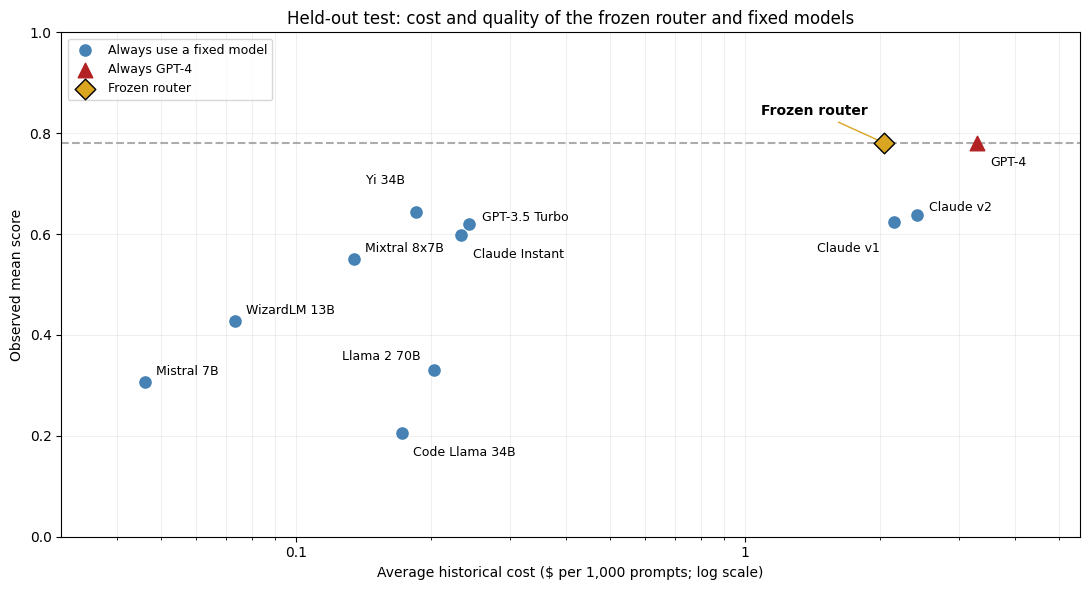

In [8]:
fig, ax = plt.subplots(figsize=(11, 6))

other_models = fixed_model_test.drop(index=REFERENCE_MODEL)
ax.scatter(
    other_models["cost_per_1000_prompts"],
    other_models["observed_mean_score"],
    color="steelblue", s=65, label="Always use a fixed model", zorder=3,
)
ax.scatter(
    1000 * reference_cost, reference_score,
    color="firebrick", marker="^", s=110,
    label="Always GPT-4", zorder=4,
)
router_point = test_model_comparison.loc[router_label]
ax.scatter(
    router_point["cost_per_1000_prompts"],
    router_point["observed_mean_score"],
    color="goldenrod", edgecolor="black", marker="D", s=110,
    label="Frozen router", zorder=5,
)

label_offsets = {
    "zero-one-ai/Yi-34B-Chat": (-8, 20),
    "gpt-3.5-turbo-1106": (9, 2),
    "claude-instant-v1": (9, -17),
    "claude-v1": (-10, -21),
    "claude-v2": (9, 3),
    "gpt-4-1106-preview": (10, -16),
    "meta/llama-2-70b-chat": (-10, 7),
    "meta/code-llama-instruct-34b-chat": (8, -16),
}
for model, point in fixed_model_test.iterrows():
    offset = label_offsets.get(model, (8, 5))
    ax.annotate(
        model_labels.get(model, model),
        (point["cost_per_1000_prompts"], point["observed_mean_score"]),
        xytext=offset, textcoords="offset points", fontsize=9,
        ha="right" if offset[0] < 0 else "left",
    )

ax.annotate(
    "Frozen router",
    (router_point["cost_per_1000_prompts"],
     router_point["observed_mean_score"]),
    xytext=(-12, 20), textcoords="offset points", ha="right",
    fontsize=10, fontweight="bold",
    arrowprops={"arrowstyle": "-", "color": "goldenrod"},
)
ax.axhline(reference_score, color="gray", linestyle="--", alpha=0.65)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}"))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set(
    title="Held-out test: cost and quality of the frozen router and fixed models",
    xlabel="Average historical cost ($ per 1,000 prompts; log scale)",
    ylabel="Observed mean score",
    ylim=(0, 1),
    xlim=(fixed_model_test["cost_per_1000_prompts"].min() * 0.65,
          test_model_comparison["cost_per_1000_prompts"].max() * 1.7),
)
ax.grid(alpha=0.2, which="both")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
plt.show()

## How many test problems did the router assign to each model?

Each test problem is counted once under its selected model. The table includes all
11 candidates, even if a model received no problems, and a total row. Percentages
use the full test set as the denominator.

In [9]:
test_model_counts = (
    test_routing_details["chosen_model"]
    .value_counts()
    .reindex(model_names, fill_value=0)
    .rename("problem_count")
    .to_frame()
)
test_model_counts.index.name = "chosen_model"
test_model_counts["percent_of_test_problems"] = (
    100 * test_model_counts["problem_count"] / len(test_routing_details)
)
test_model_counts = test_model_counts.sort_values(
    "problem_count", ascending=False, kind="stable"
)

assert test_model_counts["problem_count"].sum() == len(test_questions)
assert test_model_counts.index.is_unique
assert set(test_model_counts.index) == set(model_names)

test_model_counts_with_total = pd.concat([
    test_model_counts,
    pd.DataFrame({
        "problem_count": [len(test_routing_details)],
        "percent_of_test_problems": [100.0],
    }, index=pd.Index(["Total"], name="chosen_model")),
])

display(test_model_counts_with_total.style.format({
    "problem_count": "{:,.0f}",
    "percent_of_test_problems": "{:.2f}%",
}))

,problem_count,percent_of_test_problems
chosen_model,,
gpt-4-1106-preview,"5,083",69.63%
claude-v2,898,12.30%
claude-instant-v1,560,7.67%
zero-one-ai/Yi-34B-Chat,549,7.52%
gpt-3.5-turbo-1106,77,1.05%
mistralai/mistral-7b-chat,42,0.58%
mistralai/mixtral-8x7b-chat,32,0.44%
meta/code-llama-instruct-34b-chat,29,0.40%
claude-v1,26,0.36%


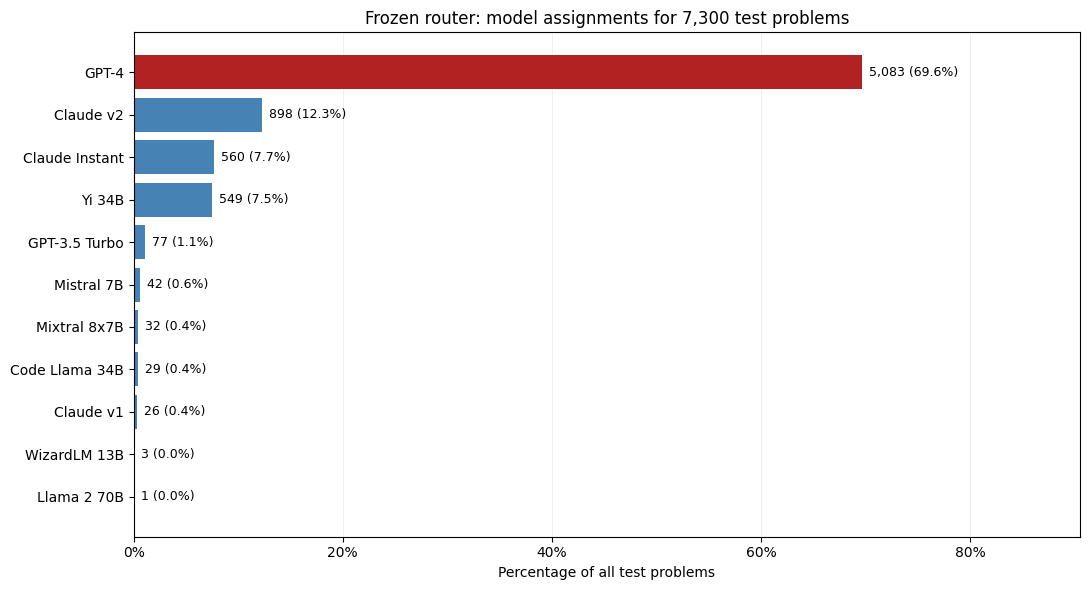

In [10]:
fig, ax = plt.subplots(figsize=(11, 6))
bar_colors = [
    "firebrick" if model == REFERENCE_MODEL else "steelblue"
    for model in test_model_counts.index
]
bars = ax.barh(
    [model_labels.get(model, model) for model in test_model_counts.index],
    test_model_counts["percent_of_test_problems"],
    color=bar_colors,
)
ax.bar_label(
    bars,
    labels=[
        f"{count:,} ({share:.1f}%)"
        for count, share in zip(
            test_model_counts["problem_count"],
            test_model_counts["percent_of_test_problems"],
        )
    ],
    padding=5, fontsize=9,
)
ax.invert_yaxis()
ax.set(
    title=f"Frozen router: model assignments for {len(test_questions):,} test problems",
    xlabel="Percentage of all test problems",
    xlim=(0, max(1, test_model_counts["percent_of_test_problems"].max()) * 1.3),
)
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}%"))
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## Test performance by task

The panels show the 10 largest test tasks, selected by problem count. The complete
task summary is retained in `test_task_metrics`. Positive quality gaps favor the
router; positive savings mean lower recorded cost than always using GPT-4.

Intervals resample paired `question_group` clusters within each task using the
same 5,000-resample basic bootstrap as the overall comparison. These are
exploratory, pointwise 95% intervals, without adjustment across tasks. A quality
interval crossing zero does not establish equivalence. Tasks with fewer than two
prompt groups have no interval; percentage savings are undefined if GPT-4's
total cost is zero.

In [11]:
task_rows = test_routing_details.assign(
    score_gap=(
        test_routing_details["observed_score"]
        - test_routing_details["gpt4_score"]
    )
)
test_task_metrics = (
    task_rows.groupby("eval_name")
    .agg(
        problem_count=("observed_score", "size"),
        prompt_groups=("question_group", "nunique"),
        router_score=("observed_score", "mean"),
        gpt4_score=("gpt4_score", "mean"),
        quality_gap_vs_gpt4=("score_gap", "mean"),
        router_mean_cost=("observed_cost", "mean"),
        gpt4_mean_cost=("gpt4_cost", "mean"),
    )
    .sort_values("problem_count", ascending=False, kind="stable")
)
test_task_metrics["router_cost_per_1000"] = (
    1000 * test_task_metrics["router_mean_cost"]
)
test_task_metrics["gpt4_cost_per_1000"] = (
    1000 * test_task_metrics["gpt4_mean_cost"]
)
test_task_metrics["cost_savings_pct"] = 100 * (
    1 - test_task_metrics["router_mean_cost"]
    / test_task_metrics["gpt4_mean_cost"].replace(0, np.nan)
)
assert test_task_metrics["problem_count"].sum() == len(test_questions)

top_test_tasks = test_task_metrics.head(10).index
task_interval_rows = []

for task_number, task in enumerate(top_test_tasks):
    grouped_task = (
        task_rows.loc[task_rows["eval_name"].eq(task)]
        .groupby("question_group")
        .agg(
            prompts=("observed_score", "size"),
            score_gap_sum=("score_gap", "sum"),
            router_cost_sum=("observed_cost", "sum"),
            gpt4_cost_sum=("gpt4_cost", "sum"),
        )
    )
    task_data = tuple(
        grouped_task[column].to_numpy(dtype=float)
        for column in [
            "prompts", "score_gap_sum", "router_cost_sum", "gpt4_cost_sum"
        ]
    )

    # Reuse the overall statistic: paired sums preserve prompt weighting.
    # An all-zero-cost resample has undefined percentage savings.
    with np.errstate(divide="ignore", invalid="ignore"):
        if len(grouped_task) >= 2:
            task_bootstrap = bootstrap(
                task_data, comparison_statistics,
                paired=True, vectorized=True,
                n_resamples=5000, batch=128, confidence_level=0.95,
                method="basic", rng=np.random.default_rng(4200 + task_number),
            )
            lower = task_bootstrap.confidence_interval.low
            upper = task_bootstrap.confidence_interval.high
        else:
            lower = upper = np.full(3, np.nan)

    task_interval_rows.append({
        "eval_name": task,
        "quality_CI_95_lower": lower[0],
        "quality_CI_95_upper": upper[0],
        "savings_CI_95_lower": lower[2],
        "savings_CI_95_upper": upper[2],
    })

test_task_intervals = pd.DataFrame(task_interval_rows).set_index("eval_name")
test_task_plot_data = test_task_metrics.loc[top_test_tasks].join(test_task_intervals)

display(test_task_plot_data[[
    "problem_count", "prompt_groups", "router_score", "gpt4_score",
    "quality_gap_vs_gpt4", "quality_CI_95_lower", "quality_CI_95_upper",
    "cost_savings_pct", "savings_CI_95_lower", "savings_CI_95_upper",
]].round(4))

,problem_count,prompt_groups,router_score,gpt4_score,quality_gap_vs_gpt4,quality_CI_95_lower,quality_CI_95_upper,cost_savings_pct,savings_CI_95_lower,savings_CI_95_upper
eval_name,,,,,,,,,,
hellaswag,2050,2050,0.8390,0.8361,0.0029,-0.0078,0.0132,29.0979,27.1013,31.0829
grade-school-math,1483,1483,0.6548,0.6578,-0.0030,-0.0126,0.0066,52.5206,50.8053,54.2145
mmlu-professional-law,300,300,0.6367,0.6367,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
arc-challenge,291,291,0.9553,0.9553,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
winogrande,239,239,0.8033,0.8033,0.0000,0.0000,0.0000,0.3552,-0.3645,0.7104
mmlu-miscellaneous,165,165,0.9333,0.9333,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
mmlu-moral-scenarios,163,163,0.7423,0.7423,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
mmlu-professional-psychology,119,119,0.8992,0.8992,0.0000,0.0000,0.0000,0.1802,-0.1993,0.3603
mmlu-high-school-psychology,109,109,0.9174,0.9266,-0.0092,-0.0183,0.0092,1.1160,-0.5822,2.2319


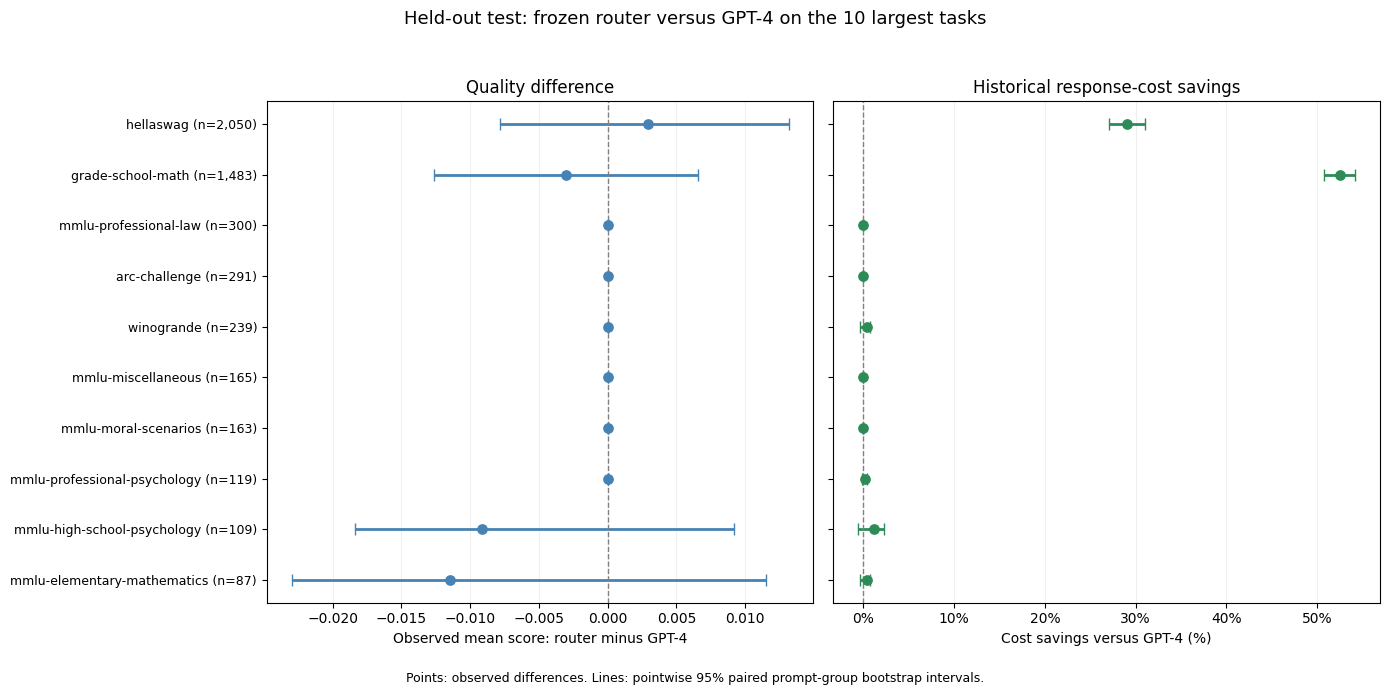

In [12]:
fig, axes = plt.subplots(figsize=(14, 7), ncols=2, sharey=True)
task_positions = np.arange(len(test_task_plot_data))
task_labels = [
    f"{task} (n={int(count):,})"
    for task, count in test_task_plot_data["problem_count"].items()
]

panel_specs = [
    (axes[0], "quality_gap_vs_gpt4", "quality_CI_95_lower",
     "quality_CI_95_upper", "steelblue", "Quality difference",
     "Observed mean score: router minus GPT-4"),
    (axes[1], "cost_savings_pct", "savings_CI_95_lower",
     "savings_CI_95_upper", "seagreen", "Historical response-cost savings",
     "Cost savings versus GPT-4 (%)"),
]

for ax, estimate_column, lower_column, upper_column, color, title, xlabel in panel_specs:
    estimates = test_task_plot_data[estimate_column].to_numpy()
    lower = test_task_plot_data[lower_column].to_numpy()
    upper = test_task_plot_data[upper_column].to_numpy()
    valid_intervals = np.isfinite(lower) & np.isfinite(upper)
    # Draw endpoints directly: a basic interval need not contain its estimate.
    ax.hlines(
        task_positions[valid_intervals], lower[valid_intervals],
        upper[valid_intervals], color=color, linewidth=2,
    )
    ax.plot(lower[valid_intervals], task_positions[valid_intervals],
            "|", color=color, markersize=8)
    ax.plot(upper[valid_intervals], task_positions[valid_intervals],
            "|", color=color, markersize=8)
    ax.scatter(estimates, task_positions, color=color, s=45, zorder=3)
    ax.axvline(0, color="gray", linestyle="--", linewidth=1)
    ax.set(title=title, xlabel=xlabel)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

axes[0].set_yticks(task_positions, labels=task_labels, fontsize=9)
axes[0].invert_yaxis()
axes[1].xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}%"))
fig.suptitle(
    "Held-out test: frozen router versus GPT-4 on the 10 largest tasks",
    fontsize=13,
)
fig.text(
    0.5, 0.02,
    "Points: observed differences. Lines: pointwise 95% paired prompt-group bootstrap intervals.",
    ha="center", fontsize=9,
)
fig.tight_layout(rect=(0, 0.05, 1, 0.95))
plt.show()